# Модель Шеллинга 1D

## Правила модели

- Кольцо из $L$ клеток; каждая занята агентом типа `0`/`1` с плотностью
  $\rho$ (остальные клетки пусты, `EMPTY = -1`).
- Окно соседей — отрезок $\pm R$ слева и справа, периодические границы.
- **Удовлетворённость**: агент счастлив, если доля «своих» среди
  **занятых** соседей $\ge T$; пустые клетки не считаются; агент без
  занятых соседей считается счастливым.
- **Один MCS** (шаг): все агенты принимают решения по состоянию
  на начало шага:
  1. с вероятностью $p$ меняют тип на случайный другой (*флип*);
  2. иначе, если несчастны, переезжают в случайную пустую клетку.

## Параметры

| обозначение | код | смысл |
|---|---|---|
| $T$ | `THRESHOLD` | порог терпимости |
| $p$ | `FLIP_PROB` | вероятность ассимиляции |
| $\rho$ | `DENSITY` | плотность занятых клеток |
| $R$ | `RADIUS` | радиус окна соседей |
| — | `LENGTH`, `SEED` | длина кольца, зерно генератора |

## Наблюдаемые

- $I$ (индекс изоляции) — суммарная доля «своих» среди занятых соседей:
  $\approx 0.5$ — случайное перемешивание, $1$ — полная сегрегация.
- happy — доля счастливых агентов по критерию $T$.

Реализация: `core/factories.py` (`make_schelling_1d`), быстрый движок
`core/fast.py` (бит-в-бит совпадает с эталоном), метрики —
`core/observables.py`.

In [1]:
from pathlib import Path
import sys

# корень проекта (там лежит core/), запуск из notebooks/ или из корня
for cand in (Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent):
    if (cand / "core" / "factories.py").exists():
        PROJ = cand
        break
else:
    raise RuntimeError("Не найден корень проекта: нужен каталог с core/factories.py")
sys.path.insert(0, str(PROJ))

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm

from core import factories
from core.fast import FastSimulation

In [2]:
# ПАРАМЕТРЫ

LENGTH    = 400        # длина кольца
THRESHOLD = 1.0 / 3.0  # T: порог терпимости
FLIP_PROB = 0.0        # p: вероятность флипа
DENSITY   = 0.7        # rho: доля занятых клеток
RADIUS    = 2          # R: окно соседей +-R
SEED      = 42         # None — недетерминированный прогон

MCS_EVOL = 300   # длительность прогона для диаграммы эволюции
MCS_KIN  = 500   # длительность прогона для кинетики

In [ ]:
def as_fast(base) -> FastSimulation:
    return FastSimulation(grid=base.grid, offsets=base.offsets,
                          n_types=base.n_types, satisfaction=base.satisfaction,
                          action=base.action, rng=base.rng)

sim = as_fast(factories.make_schelling_1d(
    LENGTH, threshold=THRESHOLD, flip_prob=FLIP_PROB,
    density=DENSITY, radius=RADIUS, seed=SEED))
print(f"собрано: L={LENGTH}, T={sim.satisfaction.threshold:.3f}, "
      f"p={sim.action.flip_prob}, rho={DENSITY}, R={RADIUS}, seed={SEED}")
print(f"занято агентов: {(sim.grid != -1).sum()} из {sim.grid.size}")

собрано: L=400, T=0.333, p=0.0, rho=0.7, R=2, seed=42
занято агентов: 280 из 400


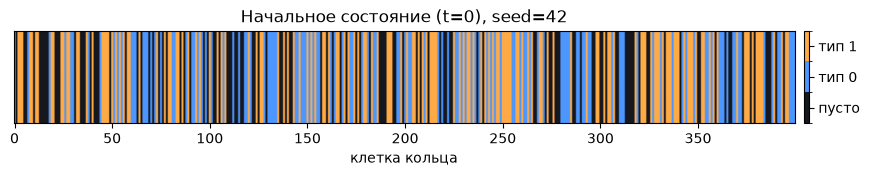

In [4]:
# палитра как в vizual/animate.py: EMPTY — тёмный, типы — синий/оранжевый
CMAP = ListedColormap(["#16181F", "#4C96FF", "#FFAA45"])
NORM = BoundaryNorm([-1.5, -0.5, 0.5, 1.5], CMAP.N)
LABELS = ["пусто", "тип 0", "тип 1"]

fig, ax = plt.subplots(figsize=(12, 1.2))
im = ax.imshow(sim.grid[None, :], cmap=CMAP, norm=NORM, aspect="auto")
ax.set_yticks([])
ax.set_xlabel("клетка кольца")
ax.set_title(f"Начальное состояние (t=0), seed={SEED}")
cbar = fig.colorbar(im, ax=ax, ticks=[-1, 0, 1], pad=0.01)
cbar.ax.set_yticklabels(LABELS)
plt.show()